In [4]:
import pandas as pd
df = pd.read_csv("bounce_detail.csv")
df.head()

,season,team,tier,outgoing,reason,last_game,ppg_before,ppg_after,ppg_after_1_5,ppg_after_6_10,expected_ppg,diff
0,2425,Leicester,other,Steve Cooper,Sacked,12,0.9,0.4,0.8,0.0,1.1940,-0.7940
1,2526,Nott'm Forest,other,Sean Dyche,Sacked,26,0.9,1.6,1.0,2.2,1.1940,0.4060
2,1819,Fulham,other,Slaviša Jokanović,Sacked,12,0.5,0.9,0.8,1.0,1.2486,-0.3486
3,2425,Everton,other,Sean Dyche,Sacked,19,0.8,1.7,2.0,1.4,1.1971,0.5029
4,2122,Aston Villa,other,Dean Smith,Sacked,11,1.0,1.6,1.8,1.4,1.2637,0.3363


In [6]:
# 1. Total row count (should be 57)
print("Row count:", len(df))

# 2. Average points per game before (should be ~0.78)
print("PPG Before:", df["ppg_before"].mean())

# 3. Average points per game after (should be ~1.21)
print("PPG After:", df["ppg_after"].mean())

Row count: 57
PPG Before: 0.7789473684210527
PPG After: 1.2087719298245612


In [9]:
# Compare averages between Big Six and other clubs
df.groupby("tier")[["ppg_before", "ppg_after"]].mean()

,ppg_before,ppg_after
tier,,
big_six,1.258333,1.683333
other,0.651111,1.082222


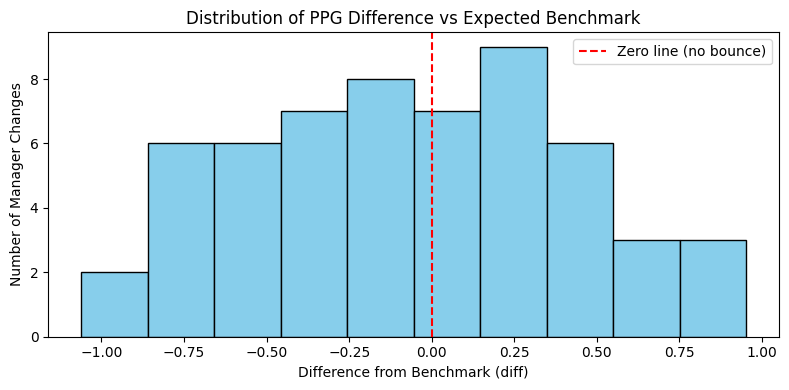

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

# Plot histogram of the 57 differences
plt.hist(df["diff"], bins=10, edgecolor="black", color="skyblue")

# Red dashed line at zero to visually check the spread
plt.axvline(0, color="red", linestyle="--", linewidth=1.5, label="Zero line (no bounce)")

plt.title("Distribution of PPG Difference vs Expected Benchmark")
plt.xlabel("Difference from Benchmark (diff)")
plt.ylabel("Number of Manager Changes")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
from scipy import stats

# Test column 'diff' against expected value 0
t_stat, p_value = stats.ttest_1samp(df["diff"], 0)

print(f"t-statistic: {t_stat:.4f}")
print(f"p-value:     {p_value:.4f}")

t-statistic: -1.0009
p-value:     0.3212
